# Isomap — Nonlinear Manifold Learning via Geodesic Distances

## 1. Definition and intuition
Isomap builds a neighborhood graph, estimates manifold geodesic distances as shortest-path distances on that graph, then applies classical MDS to those distances. It attempts to preserve global geometry along a curved manifold rather than Euclidean chord distance through ambient space.

## 2. Algorithm
1. Connect each observation to its k nearest neighbors (or points within a radius).
2. Weight edges with Euclidean distances.
3. Compute shortest-path distances across the graph.
4. Apply classical MDS to the geodesic distance matrix.

## 3. Why it works and assumptions
If local Euclidean neighborhoods approximate local manifold geometry and the graph captures correct connectivity, shortest paths can approximate geodesic distances. Too few neighbors disconnect the graph; too many create shortcuts across folds. Isomap assumes data lie near a smooth manifold and can fail with noise, short-circuit edges, disconnected graphs, or high intrinsic curvature.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import shortest_path, connected_components
from sklearn.datasets import make_s_curve
from sklearn.neighbors import kneighbors_graph
from sklearn.manifold import Isomap
from sklearn.metrics import pairwise_distances

SEED = 42
X, color = make_s_curve(n_samples=300, noise=0.04, random_state=SEED)


## 4. Isomap from scratch

The graph and shortest paths are implemented explicitly; classical MDS then embeds the geodesic distances. This is designed for small educational datasets.

In [2]:
def classical_mds(D, n_components=2):
    n = len(D)
    H = np.eye(n) - np.ones((n,n))/n
    B = -0.5 * H @ (D**2) @ H
    vals, vecs = np.linalg.eigh((B+B.T)/2)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:,order]
    return vecs[:,:n_components] * np.sqrt(np.maximum(vals[:n_components], 0))[None,:]

def isomap_scratch(X, n_neighbors=10, n_components=2):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) <= n_neighbors or n_neighbors < 2:
        raise ValueError("Invalid X or n_neighbors")
    graph = kneighbors_graph(X, n_neighbors=n_neighbors, mode="distance", include_self=False)
    graph = graph.maximum(graph.T)  # undirected union of neighborhood edges
    n_components_graph, _ = connected_components(graph, directed=False)
    if n_components_graph != 1:
        raise ValueError("Neighborhood graph is disconnected; increase n_neighbors")
    G = shortest_path(graph, directed=False, unweighted=False)
    return classical_mds(G, n_components), G

Y_scratch, G = isomap_scratch(X, n_neighbors=10, n_components=2)
print("Graph distance matrix:", G.shape, "all finite:", np.isfinite(G).all())


Graph distance matrix: (300, 300) all finite: True


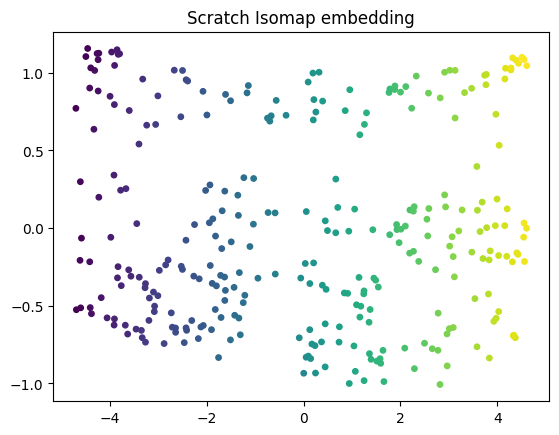

In [3]:
plt.scatter(Y_scratch[:,0], Y_scratch[:,1], c=color, cmap="viridis", s=15)
plt.title("Scratch Isomap embedding"); plt.show()


## 5. Compare with scikit-learn

In [4]:
isomap = Isomap(n_neighbors=10, n_components=2, eigen_solver="arpack")
Y_sk = isomap.fit_transform(X)
print("Scratch output shape:", Y_scratch.shape, "sklearn output shape:", Y_sk.shape)
print("Correlation of pairwise embedded distances:",
      round(float(np.corrcoef(pairwise_distances(Y_scratch).ravel(),
                              pairwise_distances(Y_sk).ravel())[0,1]), 4))
assert Y_sk.shape == Y_scratch.shape and np.isfinite(Y_sk).all()


Scratch output shape: (300, 2) sklearn output shape: (300, 2)
Correlation of pairwise embedded distances: 1.0


## 6. Hyperparameters, complexity and scaling
- `n_neighbors` / `radius`: graph connectivity and shortcut risk.
- `n_components`: output dimension.
- k-NN graph construction depends on the neighbor-search algorithm; all-pairs distances cost \(O(n^2d)\), while trees/approximate indexes may improve practical cases.
- Dense shortest-path distances use \(O(n^2)\) memory; all-pairs shortest paths can be costly. Eigendecomposition is \(O(n^3)\).
- For millions of samples, use approximate neighbor graphs, landmarks, sampling or another scalable method. A dense geodesic matrix is usually infeasible.
- GPU helps some nearest-neighbor and matrix routines, but graph connectivity and shortest paths require specialized implementations.

## 7. Best practices and tests

Try several neighbor counts and inspect graph connectivity. Isomap preserves estimated geodesic geometry, not necessarily original Euclidean distances or labels.

In [5]:
assert Y_scratch.shape == (len(X), 2)
assert np.isfinite(G).all() and np.isfinite(Y_scratch).all()
try:
    isomap_scratch(np.array([1,2,3]), 2, 2)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input shape to raise")
print("All Isomap checks passed.")


All Isomap checks passed.
